# Iterative Workflow: X (Twitter) Post Generator & Optimizer

In this workflow, we implement the **Evaluator-Optimizer Loop** pattern using 3 distinct LLMs:

1. **Generator LLM:** Crafts the initial creative post based on the given topic/theme.
2. **Evaluator LLM:** Analyzes the draft against virality, clarity, hook strength, character limits (<= 280 chars), and assigns a structured critique + score.
3. **Optimizer LLM:** Takes the critique and feedback from the evaluator, rewrites and polishes the draft, then loops back until quality thresholds are met.

```text
                   ┌──────────────────────────────┐
                   │                              ▼
[START] ──► [Generator] ──► [Evaluator] ──(if rejected)──► [Optimizer]
                                │
                         (if approved)
                                │
                                ▼
                              [END]
```

In [9]:
from typing import TypedDict, Optional, Annotated, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv

from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage, HumanMessage

In [10]:
# Define Workflow State
class TweetState(TypedDict):
    topic: str
    tweet: Optional[str]
    evaluation: Optional[Literal["approved", "not_approved"]]
    feedback: Optional[str]
    iteration: int
    max_iteration: int

In [11]:
load_dotenv()

True

In [12]:
# Setup 3 Distinct LLMs tailored for their specific roles

# 1. Generator LLM: High creativity and engaging tone for initial drafts
generator_llm = ChatGoogleGenerativeAI(
    model="gemini-flash-lite-latest",
    temperature=0.7
)

# 2. Evaluator LLM: Low temperature for strict, objective, and analytical critique
evaluator_llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.1
)

# 3. Optimizer LLM: High-reasoning model to incorporate critique and refine the post
optimizer_llm = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    temperature=0.4
)

In [13]:
# Structured Schema for the Evaluator LLM
class EvaluationSchema(BaseModel):
    evaluation: Literal["approved", "not_approved"] = Field(
        description="'approved' if viral hook, clarity, and <= 280 chars criteria are satisfied, otherwise 'not_approved'"
    )
    feedback: str = Field(description="Actionable feedback explaining weaknesses and guidance to optimize the tweet")

# Bind structured output schema to evaluator LLM
structured_evaluator_llm = evaluator_llm.with_structured_output(EvaluationSchema)

In [14]:
# Node 1: Generator
def generate_tweet(state: TweetState) -> dict:
    topic = state["topic"]
    current_iteration = state.get("iteration", 0) + 1

    system_message = SystemMessage(
        content=""" 
        You are a funny and clever Twitter/X influencer who is a FC Barcelona and Neymar fan.
        Keep your post baised to them if u taking about them
        """
    )

    human_message = HumanMessage(
        content=f"""write a short, hilarious, original tweet on the topic: {topic}

rules:
- dont use question answer format
- max 280 characters
- use observational humour, irony, sarcasm or cultural reference
- think in meme logic, punchy line, or relatable takes
- use simple days to day or genz english

This is version {current_iteration}
"""
    )

    response = generator_llm.invoke([system_message, human_message])

    # Handle both str and list content returned by Gemini
    if isinstance(response.content, list):
        tweet_text = "".join(
            p if isinstance(p, str) else p.get("text", "") for p in response.content
        ).strip()
    else:
        tweet_text = str(response.content).strip()

    return {
        "tweet": tweet_text,
        "iteration": current_iteration
    }

In [15]:
# Test generate_tweet
test_state = {
    "topic": "Remote work vs Returning to Office",
    "iteration": 0,
    "max_iteration": 3
}

output = generate_tweet(test_state)
print(f"Generated Tweet (v{output['iteration']}):\n{output['tweet']}")

Generated Tweet (v1):
Asking me to return to the office full-time after letting me work from home is crazier than PSG paying €222m just to watch us win anyway. I’m not commuting, I’m staging a tactical dive on my living room rug. Remote work is my Ballon d'Or.


In [16]:
# Node 2: Evaluator
def evaluate_tweet(state: TweetState) -> dict:
    topic = state["topic"]
    tweet = state["tweet"]
    iteration = state.get("iteration", 1)

    system_message = SystemMessage(
        content="You are a strict, viral social media editor and content strategist."
    )

    human_message = HumanMessage(
        content=f"""Evaluate the following tweet on the topic: "{topic}"

Tweet:
"{tweet}"

Evaluation Rules:
1. Is it funny, clever, and engaging?
2. Does it use meme logic, punchy lines, or relatable observations?
3. Character count check: is it strictly under 280 characters? (Current length: {len(tweet)} chars)
4. Verify it does NOT use question-answer format.

Assign:
- evaluation: 'approved' if it is genuinely funny, punchy, and <= 280 characters. Otherwise 'not_approved'.
- feedback: specific, constructive advice on how to improve the punchline, tone, or brevity.
"""
    )

    result = structured_evaluator_llm.invoke([system_message, human_message])

    print(f"\n[Evaluator v{iteration}] Verdict: {result.evaluation.upper()}")
    print(f"[Evaluator v{iteration}] Feedback: {result.feedback}")

    return {
        "evaluation": result.evaluation,
        "feedback": result.feedback
    }

In [17]:
# Conditional Router: Checks approval status & loop boundary
def route_evaluation(state: TweetState) -> Literal["approved", "optimize"]:
    evaluation = state.get("evaluation")
    iteration = state.get("iteration", 0)
    max_iteration = state.get("max_iteration", 3)

    if evaluation == "approved":
        print(f"\n🎉 Tweet Approved on iteration {iteration}!")
        return "approved"

    if iteration >= max_iteration:
        print(f"\n⚠️ Reached maximum iterations ({max_iteration}). Stopping loop.")
        return "approved"

    print(f"\n🔄 Routing to Optimizer for iteration {iteration + 1}...")
    return "optimize"

In [18]:
# Node 3: Optimizer
def optimize_tweet(state: TweetState) -> dict:
    topic = state["topic"]
    tweet = state["tweet"]
    feedback = state["feedback"]
    current_iteration = state.get("iteration", 0) + 1

    system_message = SystemMessage(
        content="You are an expert X/Twitter copywriter specializing in punchy, viral rewrites."
    )

    human_message = HumanMessage(
        content=f"""Rewrite and optimize the tweet based on editor feedback:

Topic: {topic}
Previous Tweet: "{tweet}"
Editor Feedback: "{feedback}"

Rules:
- Strictly under 280 characters.
- Directly fix the issues noted in the feedback.
- Keep it hilarious, punchy, and culturally relevant.
- Do NOT use question-answer format.
- Return ONLY the final improved tweet text, no explanation, no quotes.

This is version {current_iteration}.
"""
    )

    response = optimizer_llm.invoke([system_message, human_message])
    if isinstance(response.content, list):
        improved_tweet = "".join(
            p if isinstance(p, str) else p.get("text", "") for p in response.content
        ).strip()
    else:
        improved_tweet = str(response.content).strip()

    print(f"\n[Optimizer v{current_iteration}] Rewrote Tweet:\n\"{improved_tweet}\"")

    return {
        "tweet": improved_tweet,
        "iteration": current_iteration
    }

In [19]:
# Build Iterative Workflow Graph
graph = StateGraph(TweetState)

# Add Nodes
graph.add_node("generate_tweet", generate_tweet)
graph.add_node("evaluate_tweet", evaluate_tweet)
graph.add_node("optimize_tweet", optimize_tweet)

# Flow: START -> generate_tweet -> evaluate_tweet
graph.add_edge(START, "generate_tweet")
graph.add_edge("generate_tweet", "evaluate_tweet")

# Conditional Edge: evaluate_tweet -> END (if approved) OR optimize_tweet (if not_approved)
graph.add_conditional_edges(
    "evaluate_tweet",
    route_evaluation,
    {
        "approved": END,
        "optimize": "optimize_tweet"
    }
)

# Iterative Loop: Optimizer returns revised tweet to Evaluator!
graph.add_edge("optimize_tweet", "evaluate_tweet")

# Compile Workflow
workflow = graph.compile()

In [20]:
# Execute the Iterative Workflow
initial_input = {
    "topic": "Why Champions League nights are better than work meetings",
    "iteration": 0,
    "max_iteration": 3
}

final_result = workflow.invoke(initial_input)

print("\n" + "=" * 50)
print("🏆 FINAL TWEET")
print("=" * 50)
print(final_result["tweet"])
print(f"\nTotal Iterations: {final_result['iteration']}")
print(f"Final Status: {final_result['evaluation'].upper()}")

c:\Users\anuja\OneDrive\Desktop\coding\AI\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



[Evaluator v1] Verdict: NOT_APPROVED
[Evaluator v1] Feedback: The tweet is clever and funny, but it fails the character count check (it is currently 290 characters). Trim unnecessary words like 'unadulterated' and 'used to' to get it strictly under 280 characters for optimal viral performance.

🔄 Routing to Optimizer for iteration 2...


c:\Users\anuja\OneDrive\Desktop\coding\AI\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



[Optimizer v2] Rewrote Tweet:
"Work meetings are 45 minutes of a guy named Greg talking about "synergy" while everyone descends into depression. 

Champions League nights are 90 minutes of pure stress, but at least Neymar dribbles past 3 defenders before ruining my sleep. 

We are not the same."


c:\Users\anuja\OneDrive\Desktop\coding\AI\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(



[Evaluator v2] Verdict: APPROVED
[Evaluator v2] Feedback: The tweet hits all the criteria: it's highly relatable, uses great contrast and meme logic, avoids the question-answer format, and sits comfortably under the 280-character limit at 264 characters.

🎉 Tweet Approved on iteration 2!

🏆 FINAL TWEET
Work meetings are 45 minutes of a guy named Greg talking about "synergy" while everyone descends into depression. 

Champions League nights are 90 minutes of pure stress, but at least Neymar dribbles past 3 defenders before ruining my sleep. 

We are not the same.

Total Iterations: 2
Final Status: APPROVED


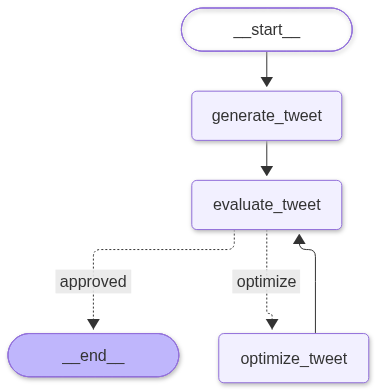

In [21]:
# Visualize Iterative Workflow Graph (Evaluator-Optimizer Loop)
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())